# Preprocessing — Weld DB (Cool & Bhadeshia, Cambridge)

**Objectif :** préparer la base de soudures pour une modélisation **multi-cibles** des propriétés mécaniques :

| Cible | Colonne | Unité |
|---|---|---|
| `yield_strength` | 31 | MPa |
| `uts` | 32 | MPa |
| `elongation` | 33 | % |
| `reduction_area` | 34 | % |
| `charpy_J` | 36 | J |

Les **variables d'entrée** sont ce qu'un ingénieur contrôle *avant* l'essai : composition, paramètres de soudage, traitement thermique post-soudage (PWHT) et, pour Charpy, la température d'essai.

Principe directeur : **tout ce qui « apprend » des données (médianes, échelles, choix des log) est appris sur le train uniquement**, après un découpage par groupe de soudure — sinon on a de la fuite de données.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 160)
BLUE = '#2a78d6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'axes.edgecolor': '#52514e', 'font.size': 9})
SEED = 42

## 1. Chargement

Le fichier est séparé par des espaces, sans en-tête, 44 colonnes sur chaque ligne (vérifié). On lit **tout en texte** (`dtype=str`) : plusieurs colonnes numériques contiennent des chaînes (`<0.01`, `67tot33res`, `158(Hv30)`…) qu'on veut traiter explicitement plutôt que laisser pandas les transformer silencieusement en NaN.

Les noms de colonnes viennent de `welddb.info`.

In [2]:
COLS = ['C','Si','Mn','S','P','Ni','Cr','Mo','V','Cu','Co','W',          # wt%
        'O_ppm','Ti_ppm','N_ppm','Al_ppm','B_ppm','Nb_ppm','Sn_ppm','As_ppm','Sb_ppm',
        'current_A','voltage_V','ac_dc','polarity','heat_input_kJmm','interpass_C','weld_type',
        'pwht_temp_C','pwht_time_h',
        'yield_strength','uts','elongation','reduction_area','charpy_temp_C','charpy_J',
        'hardness','fatt50','prim_ferrite','ferrite_2nd_phase','acicular_ferrite','martensite',
        'ferrite_carbide','weld_id']
raw = pd.read_csv('welddb.data', sep=r'\s+', header=None, names=COLS, dtype=str)
print(raw.shape)
raw.head(3)

(1652, 44)


,C,Si,Mn,S,P,Ni,Cr,Mo,V,Cu,Co,W,O_ppm,Ti_ppm,N_ppm,Al_ppm,B_ppm,Nb_ppm,Sn_ppm,As_ppm,Sb_ppm,current_A,voltage_V,ac_dc,polarity,heat_input_kJmm,interpass_C,weld_type,pwht_temp_C,pwht_time_h,yield_strength,uts,elongation,reduction_area,charpy_temp_C,charpy_J,hardness,fatt50,prim_ferrite,ferrite_2nd_phase,acicular_ferrite,martensite,ferrite_carbide,weld_id
0,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,250,14,392,466,31.9,80.6,N,N,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,0,0,N,N,N,N,-28,100,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,580,2,370,456,35.2,80.6,-38,100,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aht


## 2. Audit des valeurs manquantes

D'après la documentation, **`N` = « non rapporté dans la publication »**, et *pas* zéro. On le convertit donc en `NaN` (et non en 0).

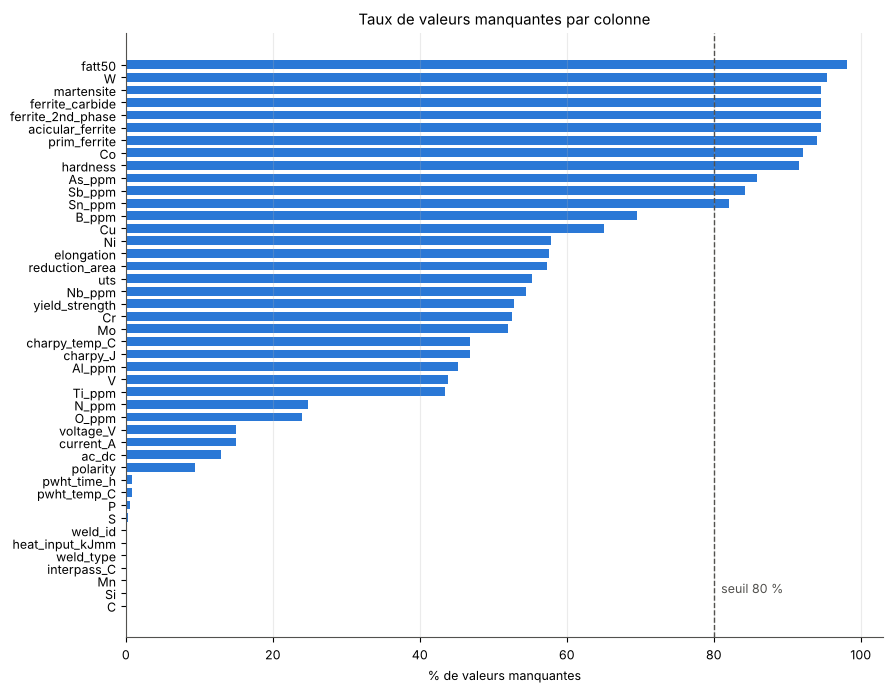

In [3]:
df = raw.replace('N', np.nan)
miss = df.isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(miss.index, miss.values * 100, color=BLUE, height=.7)
ax.axvline(80, color='#52514e', ls='--', lw=1); ax.text(81, 1, 'seuil 80 %', color='#52514e')
ax.set_xlabel('% de valeurs manquantes'); ax.set_title('Taux de valeurs manquantes par colonne')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

**Lecture :**
- Composition majeure (C, Si, Mn, S, P), apport de chaleur, type de soudure : quasi complets.
- Éléments d'alliage (Ni, Cr, Mo, V, Cu) : 35–65 % manquants — on garde, ce sont des variables métallurgiquement clés.
- Co, W, Sn, As, Sb : > 80 % manquants.
- Dureté, FATT50, microstructure : > 90 % manquants.
- Chaque cible n'est présente que sur ~45–55 % des lignes : **les lignes « traction » et les lignes « Charpy » sont souvent séparées** (suffixes `aw` / `awch` dans `weld_id`).

## 3. Nettoyage des valeurs textuelles

Inventaire des chaînes non numériques trouvées dans les colonnes numériques :

In [4]:
num_cols = [c for c in COLS if c not in ('ac_dc', 'polarity', 'weld_type', 'weld_id')]
for c in num_cols:
    s = df[c].dropna()
    bad = s[pd.to_numeric(s, errors='coerce').isna()].unique()
    if len(bad): print(f'{c:16s} {len(bad):3d} formats  ex: {list(bad[:6])}')

S                  1 formats  ex: ['<0.002']
Mo                 1 formats  ex: ['<0.01']
V                  4 formats  ex: ['<0.0005', '<0.01', '<0.005', '<5']
Cu                 1 formats  ex: ['<0.01']
Co                 1 formats  ex: ['<0.01']
W                  1 formats  ex: ['<0.1']
Ti_ppm             4 formats  ex: ['<5', '<100', '<0.01', '<10']
N_ppm              8 formats  ex: ['67tot33res', '66totndres', '61tot34res', '54totndres', '54tot24res', '52tot18res']
Al_ppm             4 formats  ex: ['<5', '<50', '<100', '<0.01']
B_ppm              2 formats  ex: ['<5', '<10']
Nb_ppm             4 formats  ex: ['<5', '<6', '<100', '<50']
Sn_ppm             2 formats  ex: ['<100', '<10']
As_ppm             1 formats  ex: ['<100']
Sb_ppm             2 formats  ex: ['<100', '<10']
interpass_C        1 formats  ex: ['150-200']
hardness          50 formats  ex: ['158(Hv30)', '155(Hv30)', '153(Hv30)', '161(Hv30)', '168(Hv30)', '203(Hv30)']
prim_ferrite       1 formats  ex: ['<1']


### Décisions

| Cas | Exemple | Décision | Justification |
|---|---|---|---|
| Valeur sous la limite de détection | `<0.01`, `<5` | **x / 2** | Convention standard pour les données censurées : la vraie valeur est entre 0 et x ; 0 sous-estime, x surestime. |
| Azote « total / résiduel » | `67tot33res`, `66totndres` | **valeur totale** (67) | Les autres lignes rapportent l'azote total ; on reste homogène. |
| Intervalle de température entre passes | `150-200` | **milieu** (175) | Meilleure estimation ponctuelle. |
| Dureté avec échelles mixtes | `257`, `158(Hv30)`, `459Hv10` | **colonne supprimée** (voir §6) | 92 % manquante et échelles de charge différentes, non directement comparables. |

In [5]:
def parse_value(v):
    if pd.isna(v): return np.nan
    v = str(v).strip()
    if v.startswith('<'): return float(v[1:]) / 2               # censuré -> x/2
    m = re.fullmatch(r'(\d+(?:\.\d+)?)tot.*res', v)               # azote total/résiduel
    if m: return float(m.group(1))
    m = re.fullmatch(r'(\d+(?:\.\d+)?)-(\d+(?:\.\d+)?)', v)       # intervalle
    if m: return (float(m.group(1)) + float(m.group(2))) / 2
    try: return float(v)
    except ValueError: return np.nan

df = df.drop(columns='hardness')
num_cols.remove('hardness')
for c in num_cols:
    df[c] = df[c].map(parse_value).astype(float)
df[num_cols].describe().T[['count', 'min', '50%', 'max']]

,count,min,50%,max
C,1652.0,0.029,0.074,0.18
Si,1652.0,0.040,0.320,1.14
Mn,1652.0,0.270,1.270,2.25
S,1648.0,0.001,0.007,0.14
P,1642.0,0.002,0.010,0.25
Ni,697.0,0.000,0.067,3.50
Cr,784.0,0.000,0.530,10.20
Mo,793.0,0.000,0.340,1.50
V,928.0,0.000,0.005,2.50
Cu,578.0,0.000,0.030,1.63


## 4. Corrections d'unités

En comparant chaque valeur à la plage habituelle de sa colonne, on trouve des valeurs **saisies dans la mauvaise unité** (wt% au lieu de ppm et inversement) :

| Lignes | Colonne | Valeur | Problème | Correction |
|---|---|---|---|---|
| `EPRI-TR-101394s-E9*` | Al (ppm) | 0.004–0.014 | 0.01 ppm d'Al est irréaliste : ce sont des wt% | × 10 000 → 40–140 ppm |
| `PantK-1990-*` | Al, Ti (ppm) | `<0.01` | même erreur (limite de détection en wt%) | → 0.005 wt% × 10 000 = 50 ppm |
| `Ditt-*`, `Mart-*` | Sn, As, Sb (ppm) | 0.001–0.31 | même erreur, toute la série est en wt% | × 10 000 (colonnes supprimées ensuite, mais corrigées pour l'export propre) |
| `EvansLetterC*` | V (wt%) | `<5` | 5 wt% de V est absurde pour ces aciers C-Mn-Mo : c'est `<5 ppm` | → 2.5 ppm = 0.00025 wt% |

On corrige **par source** (identifiée via `weld_id`) et uniquement les valeurs < 1 de ces sources (certaines lignes EPRI/PantK sont, elles, bien en ppm : `160`, `<100`). Un seuil global appliqué à toute la base risquerait de toucher une vraie petite valeur (ex. Ti = 0.5 ppm chez `Stil-TiB`, laissé tel quel).
Les 0 exacts restent des 0 (valeur réellement mesurée nulle).

In [6]:
FIXES = {('EPRI-TR-101394', 'Al_ppm'), ('PantK-1990', 'Al_ppm'), ('PantK-1990', 'Ti_ppm'),
         ('Ditt-', 'Sn_ppm'), ('Ditt-', 'As_ppm'), ('Ditt-', 'Sb_ppm'),
         ('Mart-', 'Sn_ppm'), ('Mart-', 'As_ppm'), ('Mart-', 'Sb_ppm')}
for src, c in sorted(FIXES):
    mask = df.weld_id.str.startswith(src) & df[c].between(1e-9, 1, inclusive='left')  # 0 exact = vrai 0
    df.loc[mask, c] *= 1e4
    print(f'{src:16s} {c:7s} {mask.sum():3d} valeurs x 1e4 -> {sorted(df.loc[mask, c].round(0).unique().tolist())[:6]}')
# Vanadium donné en ppm ("<5") dans une colonne en wt%
mask_v = raw['V'].eq('<5')
df.loc[mask_v, 'V'] = 2.5 / 1e4
print('V corrigé sur', mask_v.sum(), 'lignes')

Ditt-            As_ppm   20 valeurs x 1e4 -> [30.0]
Ditt-            Sb_ppm   20 valeurs x 1e4 -> [10.0]
Ditt-            Sn_ppm   20 valeurs x 1e4 -> [20.0]
EPRI-TR-101394   Al_ppm   10 valeurs x 1e4 -> [40.0, 50.0, 130.0, 140.0]
Mart-            As_ppm   70 valeurs x 1e4 -> [80.0, 100.0, 160.0, 300.0, 320.0, 340.0]
Mart-            Sb_ppm   70 valeurs x 1e4 -> [80.0]
Mart-            Sn_ppm   70 valeurs x 1e4 -> [80.0, 90.0]
PantK-1990       Al_ppm   16 valeurs x 1e4 -> [50.0]
PantK-1990       Ti_ppm   16 valeurs x 1e4 -> [50.0]
V corrigé sur 9 lignes


## 5. Variables catégorielles

### Courant / polarité
Les colonnes `ac_dc` et `polarity` sont liées : en AC il n'y a pas de polarité (codée `0` dans la base), et un `+` sans type de courant implique du DC. On les **fusionne en une seule variable** `electrode` ∈ {`DC+`, `DC-`, `AC`, `unknown`}, ce qui évite des combinaisons incohérentes et une modalité « 0 » artificielle.

In [7]:
print(pd.crosstab(df.ac_dc.fillna('NaN'), df.polarity.fillna('NaN')))
def electrode(r):
    if r.ac_dc == 'AC': return 'AC'
    if r.polarity in ('+', '-'): return 'DC' + r.polarity      # '+' sans type -> DC
    return 'unknown'
df['electrode'] = df.apply(electrode, axis=1)
df = df.drop(columns=['ac_dc', 'polarity'])
df.electrode.value_counts()

polarity     +  -   0  NaN
ac_dc                     
AC           4  0  38    0
DC        1388  7   0    0
NaN         59  0   0  156


electrode
DC+        1447
unknown     156
AC           42
DC-           7
Name: count, dtype: int64

### Type de soudure
La documentation indique des synonymes (`ShMA = MMA`, `SA = SMA`), et certaines modalités sont très rares (4 à 18 lignes). On regroupe par **famille de procédé** pour éviter des modalités qu'un modèle ne pourra pas apprendre :

| Famille | Codes | Raison |
|---|---|---|
| `MMA` | MMA, ShMA | synonymes |
| `SA` | SA, SAA, NGSAW | arc submergé (auto / chanfrein étroit) |
| `TSA` | TSA | arc submergé tandem — assez de lignes (87) pour rester séparé |
| `FCA` | FCA | fil fourré |
| `GMA_GTA` | GMAA, NGGMA, GTAA | procédés sous gaz, 15 lignes au total |

In [8]:
WELD_MAP = {'MMA': 'MMA', 'ShMA': 'MMA', 'SA': 'SA', 'SAA': 'SA', 'NGSAW': 'SA', 'TSA': 'TSA',
            'FCA': 'FCA', 'GMAA': 'GMA_GTA', 'NGGMA': 'GMA_GTA', 'GTAA': 'GMA_GTA'}
assert set(df.weld_type.unique()) <= set(WELD_MAP)
df['weld_type'] = df.weld_type.map(WELD_MAP)
df.weld_type.value_counts()

weld_type
MMA        1180
SA          283
FCA          87
TSA          87
GMA_GTA      15
Name: count, dtype: int64

## 6. Sélection des lignes et colonnes

**Lignes supprimées :**
- 13 lignes `Gar&K-1975-*ht` : le suffixe `ht` signifie « traitée thermiquement » mais la température et la durée du PWHT ne sont pas données. Le PWHT a un effet majeur sur toutes les cibles ; imputer une médiane (souvent 250 °C, un simple dégazage) serait faux. On les retire.
- Lignes sans **aucune** des 5 cibles : inutilisables en supervisé.

**Colonnes supprimées :**
- `fatt50`, et les 5 colonnes de **microstructure** : > 94 % manquantes *et* ce sont des **résultats** du soudage, pas des paramètres d'entrée → les utiliser comme features serait de la fuite (on ne les connaît pas au moment de concevoir la soudure).
- `Co`, `W`, `Sn`, `As`, `Sb` : > 80 % manquantes — c'est aussi ce qu'ont fait les auteurs (« columns which only have a small amount of data have been removed »).
- `hardness` : déjà retirée (§3).
- `weld_id` : identifiant, gardé comme **métadonnée** seulement.

In [9]:
TARGETS = ['yield_strength', 'uts', 'elongation', 'reduction_area', 'charpy_J']
n0 = len(df)
df = df[~(df.weld_id.str.startswith('Gar&K') & df.pwht_temp_C.isna())]
print('PWHT inconnu supprimé :', n0 - len(df))
n1 = len(df)
df = df[df[TARGETS].notna().any(axis=1)]
print('Sans aucune cible supprimé :', n1 - len(df))

DROP = ['fatt50', 'prim_ferrite', 'ferrite_2nd_phase', 'acicular_ferrite', 'martensite',
        'ferrite_carbide', 'Co', 'W', 'Sn_ppm', 'As_ppm', 'Sb_ppm']
df = df.drop(columns=DROP).reset_index(drop=True)
print('Shape :', df.shape)

PWHT inconnu supprimé : 13
Sans aucune cible supprimé : 105
Shape : (1534, 31)


## 7. Contrôles de cohérence physique

In [10]:
checks = {
    'YS > UTS': (df.yield_strength > df.uts).sum(),
    'Charpy sans température (ou inverse)': (df.charpy_J.isna() != df.charpy_temp_C.isna()).sum(),
    'PWHT temp > 0 mais durée = 0 (ou inverse)': ((df.pwht_temp_C > 0) != (df.pwht_time_h > 0)).sum(),
    'Pourcentages hors [0, 100]': ((df[['elongation', 'reduction_area']] < 0) | (df[['elongation', 'reduction_area']] > 100)).sum().sum(),
    'Lignes strictement dupliquées': df.duplicated().sum(),
}
pd.Series(checks, name='nb')

YS > UTS                                     0
Charpy sans température (ou inverse)         0
PWHT temp > 0 mais durée = 0 (ou inverse)    0
Pourcentages hors [0, 100]                   0
Lignes strictement dupliquées                0
Name: nb, dtype: int64

Aucune incohérence. Côté valeurs extrêmes (ex. Cr jusqu'à 10 %, O jusqu'à 1650 ppm, Charpy jusqu'à 270 J) : elles correspondent à des familles réelles (aciers 9Cr, vieilles électrodes rutiles, etc.). **On ne supprime pas d'outliers** : ce sont des données de littérature, pas du bruit de capteur, et les retirer amputerait le domaine de validité du modèle. On les traite plutôt par transformation log (§9).

## 8. Groupes de soudure et découpage train / test

Point crucial : **une même soudure apparaît sur plusieurs lignes** (une ligne traction, une ou plusieurs lignes Charpy à différentes températures, parfois avant/après PWHT). Un split aléatoire mettrait la même soudure dans le train et le test → score de test **trop optimiste**.

On définit un `weld_group` = mêmes composition + mêmes paramètres de soudage (hors PWHT et température Charpy), puis on découpe **par groupe** (80 / 20). Les mêmes groupes devront servir en validation croisée (`GroupKFold`).

In [11]:
GROUP_KEYS = ['C','Si','Mn','S','P','Ni','Cr','Mo','V','Cu','O_ppm','Ti_ppm','N_ppm','Al_ppm',
              'B_ppm','Nb_ppm','current_A','voltage_V','electrode','heat_input_kJmm','interpass_C','weld_type']
df['weld_group'] = df[GROUP_KEYS].map(str).agg('|'.join, axis=1).factorize()[0]
print(f"{len(df)} lignes -> {df.weld_group.nunique()} soudures distinctes")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df.weld_group))
train, test = df.iloc[tr_idx].copy(), df.iloc[te_idx].copy()
assert not set(train.weld_group) & set(test.weld_group)
pd.DataFrame({'train': train[TARGETS].notna().sum(), 'test': test[TARGETS].notna().sum()}).T.assign(lignes=[len(train), len(test)])

1534 lignes -> 606 soudures distinctes


,yield_strength,uts,elongation,reduction_area,charpy_J,lignes
train,611,590,548,554,683,1206
test,156,148,139,138,196,328


## 9. Transformation des features (apprise sur le train)

Pipeline scikit-learn, **ajusté sur le train seulement** puis appliqué au test :

1. **log1p** sur les variables très asymétriques (|skew| > 1 sur le train) — typiquement les éléments en ppm, les éléments d'alliage (Ni, Cr, V, Cu), le courant / la tension. Réduit l'influence des valeurs extrêmes.
2. **Imputation par la médiane** + **indicateurs de manquant** (`missingindicator_*`).
   - Pourquoi pas 0 ? La doc dit explicitement que `N` ≠ 0.
   - Pourquoi des indicateurs ? Le fait qu'un élément ne soit pas rapporté est informatif (souvent : élément non ajouté volontairement). L'indicateur laisse le modèle l'exploiter.
   - Pour `charpy_temp_C`, l'indicateur signifie simplement « ligne Charpy ».
3. **StandardScaler** : moyenne 0, écart-type 1 (nécessaire pour réseaux de neurones, SVR, régressions régularisées ; sans effet sur les arbres).
4. **One-hot** pour `weld_type` et `electrode` (`handle_unknown='ignore'` pour la robustesse).

Les **cibles ne sont pas imputées** : chaque modèle (ou chaque sortie d'un modèle multi-tâche) s'entraîne uniquement sur les lignes où sa cible est mesurée.

In [12]:
CAT = ['weld_type', 'electrode']
NUM = [c for c in df.columns if c not in TARGETS + CAT + ['weld_id', 'weld_group']]
skew = train[NUM].skew()
LOG = [c for c in NUM if abs(skew[c]) > 1 and train[c].min() >= 0]
LIN = [c for c in NUM if c not in LOG]
print('log1p :', LOG); print('linéaire :', LIN)

num_pipe = lambda log: Pipeline(([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))] if log else []) + [
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler())])
pre = ColumnTransformer([
    ('log', num_pipe(True), LOG),
    ('lin', num_pipe(False), LIN),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)],
    verbose_feature_names_out=False)
X_train = pd.DataFrame(pre.fit_transform(train), columns=pre.get_feature_names_out(), index=train.index)
X_test = pd.DataFrame(pre.transform(test), columns=pre.get_feature_names_out(), index=test.index)
print(X_train.shape, X_test.shape, '| NaN restants :', X_train.isna().sum().sum() + X_test.isna().sum().sum())

log1p : ['Si', 'S', 'P', 'Ni', 'Cr', 'V', 'Cu', 'O_ppm', 'Ti_ppm', 'N_ppm', 'Al_ppm', 'B_ppm', 'Nb_ppm', 'current_A', 'voltage_V', 'heat_input_kJmm']
linéaire : ['C', 'Mn', 'Mo', 'interpass_C', 'pwht_temp_C', 'pwht_time_h', 'charpy_temp_C']


(1206, 48) (328, 48) | NaN restants : 0


In [13]:
# Effet du log1p sur l'asymétrie (train)
pd.DataFrame({'skew brut': train[LOG].skew(), 'skew après log1p': np.log1p(train[LOG]).skew()}).round(2).sort_values('skew brut', ascending=False)

,skew brut,skew après log1p
P,9.56,9.32
S,8.66,8.46
B_ppm,3.93,2.25
N_ppm,2.96,1.12
Cu,2.73,2.14
Ti_ppm,2.62,-0.66
voltage_V,2.54,1.78
Ni,2.22,1.78
Nb_ppm,2.22,0.44
heat_input_kJmm,2.17,1.37


## 10. Distribution des cibles (train)

- **YS, UTS, élongation** : distributions unimodales, légère asymétrie → pas de transformation par défaut.
- **Réduction d'aire** : asymétrique à gauche (bornée près de 80 %) — à surveiller dans les résidus.
- **Charpy** : deux pics très nets à **100 J** et **28 J** (≈ 54 % des lignes Charpy). Ce ne sont pas des énergies « mesurées au hasard » : beaucoup de publications rapportent la **température de transition** à laquelle la soudure atteint 100 J ou 28 J (critères normalisés). La paire (température, énergie) reste un point valide de la courbe de transition, donc on garde ces lignes, mais :
  - un modèle d'énergie à température donnée verra beaucoup de valeurs « figées » ;
  - une alternative pertinente est de reformuler la cible en **T(100 J) / T(28 J)** pour ces soudures.
  
  *Ne pas* ajouter d'indicateur « ligne à 100 J » comme feature : ce serait donner la cible au modèle.

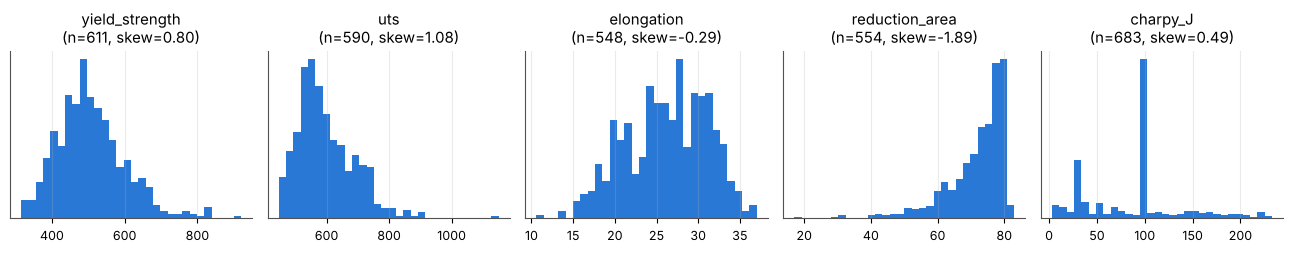

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.6))
for ax, t in zip(axes, TARGETS):
    s = train[t].dropna(); ax.hist(s, bins=30, color=BLUE)
    ax.set_title(f'{t}\n(n={len(s)}, skew={s.skew():.2f})'); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 11. Export
- `welddb_clean.csv` : données nettoyées **non imputées / non normalisées** (+ `weld_id`, `weld_group`) — pour exploration ou pour refaire un autre pipeline.
- `train_processed.csv`, `test_processed.csv` : features transformées + cibles brutes (NaN = non mesurée) + `weld_group`.
- `preprocessor.joblib` : le pipeline ajusté, à réutiliser via `pre.transform(nouvelles_donnees)`.

In [15]:
df.to_csv('welddb_clean.csv', index=False)
X_train.join(train[TARGETS + ['weld_group']]).to_csv('train_processed.csv', index=False)
X_test.join(test[TARGETS + ['weld_group']]).to_csv('test_processed.csv', index=False)
joblib.dump(pre, 'preprocessor.joblib')
print('OK')

OK


## 12. Utilisation pour la modélisation multi-cibles

```python
tr = pd.read_csv('train_processed.csv')
feats = [c for c in tr.columns if c not in TARGETS + ['weld_group']]
for t in TARGETS:
    m = tr[t].notna()                       # uniquement les lignes où la cible est mesurée
    model.fit(tr.loc[m, feats], tr.loc[m, t])
    # validation croisée : GroupKFold(n_splits=5).split(..., groups=tr.loc[m, 'weld_group'])
```

Pour un modèle **multi-sorties** unique (ex. réseau de neurones), utiliser une loss masquée qui ignore les cibles NaN.

## Récapitulatif des décisions

| # | Étape | Décision |
|---|---|---|
| 1 | `N` | → NaN, jamais 0 |
| 2 | `<x` | → x/2 |
| 3 | Azote `XtotYres` | → total X |
| 4 | Interpass `150-200` | → 175 |
| 5 | Unités erronées | Al/Sn/As/Sb (EPRI, Mart) ×10⁴ ; V `<5` ppm → wt% |
| 6 | Courant + polarité | fusion en `electrode` (DC+, DC-, AC, unknown) |
| 7 | Type de soudure | 10 codes → 5 familles |
| 8 | PWHT inconnu | 13 lignes supprimées |
| 9 | Colonnes > 80 % NaN ou post-soudage | supprimées (Co, W, Sn, As, Sb, dureté, FATT, microstructure) |
| 10 | Outliers | conservés (données réelles), atténués par log1p |
| 11 | Split | par groupe de soudure (pas de fuite) |
| 12 | Features | log1p (skew > 1) → médiane + indicateurs → standardisation ; one-hot |
| 13 | Cibles | non imputées ; masque par cible |
| 14 | Charpy à 100 J / 28 J | conservées, signalées (critères de transition) — reformulation possible |